In [1]:
import pandas as pd
import numpy as np
import xarray as xr

import matplotlib.pyplot as plt

from xgboost import XGBRegressor
from scipy.stats import genextreme
from scipy.signal import find_peaks
from utils.tv_var.periodic_var import PeriodicVAR

In [2]:
import pickle, json, glob
from utils.pit.piece_wise_marginal import from_normal

point = 'p102'
waves_df = pd.read_csv(f"inputs/waves_bulk_{point}.csv", index_col=0, parse_dates=True)
tr_ = pickle.load(open(f"outputs/marginal/transformacion_{point}.pkl", "rb"))
marg, harm_z = tr_["marg"], tr_["harm_z"]

def hs_desde_z(z):
    """Serie de Z (Hs) → Hs en metros, deshaciendo la armónica, Φ y la marginal."""
    zz = pd.DataFrame({"VHM0": z, "VTM02": 0.0}, index=z.index)      # la armónica se ajustó con las dos columnas
    z0 = harm_z.inverse_transform(zz)["VHM0"].clip(-6.36, 6.36)    # mismo límite que to_normal (eps=1e-10)
    return pd.Series(marg["VHM0"].ppf(from_normal(z0).values), index=z.index)

SUF = "_simple_est_trozos8"                                   # "" para el modelo completo "_simple" para el modelo simple

#### Emulador completo: PCs simuladas (PVAR, 03) → f (XGB, 04B) → ruido (05C) → Hs
Cada simulación de 03 son 87 años de PCs 6-horarias. Aquí se pasan a Hs horaria y se guardan solo los máximos anuales y algunas estadísticas (la serie completa de la primera simulación también, para mirarla).

In [3]:
#### Regresión final de 04B
xgb_final = XGBRegressor()
xgb_final.load_model(f"outputs/xgb_pit_{point}/xgb_final.json")
feat = json.load(open(f"outputs/xgb_pit_{point}/xgb_features.json"))
cols, lags = feat["columns"], feat["lags_h"]

#### Modelo de ruido final de 05C
resid = pd.read_csv(f"outputs/xgb_pit_{point}/residuos_horarios.csv", index_col=0, parse_dates=True)
esc = pickle.load(open(f"outputs/xgb_pit_{point}/escala_simple_est.pkl", "rb"))
bordes, sigma, pools_r, results_u, L = esc["bordes"], esc["sigma"], esc["pools_r"], esc["results_u"], esc["L"]
SUAVIZADO_H = esc.get("suavizado_h", 1)
print(f"lags {lags} | f suavizada {SUAVIZADO_H} h")

e_u = results_u.resid_["r"].asfreq("h")
ev = e_u.values
inicios = np.flatnonzero(np.convolve(~np.isnan(ev), np.ones(L), "valid") == L)

def ruido_bloques(n, L, rng):
    out = np.empty(n)
    t = 0
    while t < n:
        s = rng.choice(inicios)
        m = min(L, n - t)
        out[t:t + m] = ev[s:s + m]
        t += m
    return out

def mapear(r, dec):
    """Mapeo de cuantiles por clase (decil × estación): r toma la forma de r_oof de su clase."""
    out = np.empty(len(r))
    for k in pools_r:
        m = dec == k
        if m.sum():
            rk = (pd.Series(r.values[m]).rank().values - 0.5) / m.sum()
            out[m] = np.quantile(pools_r[k], rk)
    return pd.Series(out, index=r.index)

lags [0, 6, 12, 18, 24, 30, 36] | f suavizada 1 h


In [4]:
def f_desde_pcs(pcs):
    """PCs 6-horarias → f horaria (mismos lags y columnas que 04B, interpolada y suavizada como en 05C)."""
    X = pd.concat({f"l{l}": pcs.shift(freq=pd.Timedelta(hours=l)) for l in lags}, axis=1).reindex(pcs.index)
    X.columns = [f"{c_}_l{l[1:]}" for l, c_ in X.columns]
    X = X.dropna()[cols]
    f_6h = pd.Series(xgb_final.predict(X), index=X.index)
    f_h = f_6h.resample("h").interpolate()
    if SUAVIZADO_H > 1:
        f_h = f_h.rolling(SUAVIZADO_H, center=True, min_periods=1).mean()
    return f_h

def estacion(ix):
    return np.where(ix.month.isin([11, 12, 1, 2, 3]), 0, np.where(ix.month.isin([4, 10]), 1, 2))

def hs_desde_f(f_h, rng):
    """f horaria → Hs horaria con el ruido mapeado por decil × estación."""
    dec = np.digitize(f_h, bordes)
    clase = dec + 10 * estacion(f_h.index)
    sig = pd.Series(sigma.loc[dec].values, index=f_h.index)                 # σ = 1 en la versión simplificada
    ruido_df = pd.DataFrame(ruido_bloques(len(f_h), L, rng), index=f_h.index, columns=["r"])
    u = results_u.simulate(noise=ruido_df, burn=24 * 30)["r"]
    return hs_desde_z(f_h + mapear(u * sig, clase))

In [5]:
#### Comprobación con la historia: PCs reales → f debe coincidir con la f de 04B (test 2016–2025)
pcs_hist = pd.read_csv("outputs/pca/pcs_msl_sel_6h.csv", index_col=0, parse_dates=True)
f_hist = f_desde_pcs(pcs_hist.loc["1984-12-01":"2025-12-31"]).loc["1985":"2025"]
f_04B = resid["f"].asfreq("h")
if SUAVIZADO_H > 1:
    f_04B = f_04B.rolling(SUAVIZADO_H, center=True, min_periods=1).mean()
print(f"corr f (aquí) vs f (04B) en test: {f_hist.loc['2016':'2025'].corr(f_04B.loc['2016':'2025']):.4f}  (≈ 1)")

corr f (aquí) vs f (04B) en test: 1.0000  (≈ 1)


In [6]:
#### Bucle sobre las simulaciones del PVAR: guarda Hs y f horarias de todas las simulaciones
import time, os
ficheros = sorted(glob.glob("outputs/var_trozos_K8/simulaciones/sim_*.parquet"))
n_sims = 100

carpeta = f"outputs/xgb_pit_{point}/emulador{SUF}"            # p. ej. outputs/xgb_pit_p102/emulador_simple/
os.makedirs(carpeta, exist_ok=True)

u_hist = waves_df.loc["1985":"2025", "VHM0"].quantile(0.99)   # mismo umbral de temporal que 05D
am_hs, am_f, stats, q_f = [], [], [], []
for i, fic in enumerate(ficheros[:n_sims]):
    t = time.time()
    pcs_sim = pd.read_parquet(fic).astype("float64")
    f_h = f_desde_pcs(pcs_sim).loc[str(pcs_sim.index[0].year + 1):]          # fuera el primer año
    hs = hs_desde_f(f_h, np.random.default_rng(i))

    #### serie horaria completa de cada simulación (Hs y f), float32
    pd.DataFrame({"VHM0": hs, "f": f_h}).astype("float32").to_parquet(f"{carpeta}/sim_{i:03d}.parquet")

    am_hs.append(hs.groupby(hs.index.year).max().reset_index(drop=True))
    am_f.append(f_h.groupby(f_h.index.year).max().reset_index(drop=True))
    q_f.append(f_h.quantile([0.5, 0.9, 0.99, 0.999]))
    n_anos = hs.index.year.nunique()
    stats.append({"q99": hs.quantile(0.99), "q999": hs.quantile(0.999), "max": hs.max(),
                  "temporales/10 años": len(find_peaks(hs.values, height=u_hist, distance=72)[0]) * 10 / n_anos})
    print(f"sim {i:03d} ({time.time() - t:.0f} s)")

am_hs = pd.concat(am_hs, axis=1)                             # (años, n_sims)
am_f = pd.concat(am_f, axis=1)
stats = pd.DataFrame(stats)
pickle.dump({"am_hs": am_hs, "am_f": am_f, "stats": stats}, open(f"outputs/xgb_pit_{point}/am_pvar{SUF}.pkl", "wb"))

sim 000 (17 s)
sim 001 (17 s)
sim 002 (17 s)
sim 003 (17 s)
sim 004 (17 s)
sim 005 (17 s)
sim 006 (18 s)
sim 007 (21 s)
sim 008 (22 s)
sim 009 (22 s)
sim 010 (21 s)
sim 011 (22 s)
sim 012 (22 s)
sim 013 (23 s)
sim 014 (22 s)
sim 015 (22 s)
sim 016 (22 s)
sim 017 (21 s)
sim 018 (22 s)
sim 019 (21 s)


#### 1. ¿El PVAR da una f como la histórica?

In [7]:
q_f_sim = pd.concat(q_f, axis=1)
tabla_f = pd.DataFrame({"f histórica": f_hist.quantile([0.5, 0.9, 0.99, 0.999]),
                        "f PVAR med": q_f_sim.median(axis=1),
                        "f PVAR lo": q_f_sim.quantile(0.025, axis=1), "f PVAR hi": q_f_sim.quantile(0.975, axis=1)})
print(tabla_f.round(3).to_string())

am_f_hist = f_hist.groupby(f_hist.index.year).max()
print(f"\nmáx. anual de f: histórica {am_f_hist.mean():.2f} ± {am_f_hist.std():.2f} | "
      f"PVAR {am_f.values.mean():.2f} ± {am_f.values.std():.2f}")

       f histórica  f PVAR med  f PVAR lo  f PVAR hi
0.500       -0.044      -0.030     -0.037     -0.012
0.900        0.971       0.848      0.826      0.865
0.990        1.939       1.794      1.741      1.815
0.999        2.657       2.474      2.420      2.564

máx. anual de f: histórica 2.66 ± 0.31 | PVAR 2.45 ± 0.33


#### 2. Hs: cuantiles altos y temporales

In [8]:
hs_obs = waves_df.loc["1985":"2025", "VHM0"]
n_obs = len(find_peaks(hs_obs.values, height=u_hist, distance=72)[0]) * 10 / hs_obs.index.year.nunique()
print(f"obs : q99 {hs_obs.quantile(0.99):.2f} | q999 {hs_obs.quantile(0.999):.2f} | max {hs_obs.max():.2f} | temporales/10 años {n_obs:.0f}")
print("05D (f histórica): temporales/10 años ≈ 67–81")
print(stats.quantile([0.025, 0.5, 0.975]).round(2))

obs : q99 3.73 | q999 5.30 | max 7.78 | temporales/10 años 62
05D (f histórica): temporales/10 años ≈ 67–81
        q99  q999   max  temporales/10 años
0.025  3.56  5.27  7.51               43.90
0.500  3.65  5.40  8.21               46.80
0.975  3.73  5.60  9.10               51.92


#### 3. Máximos anuales y periodos de retorno

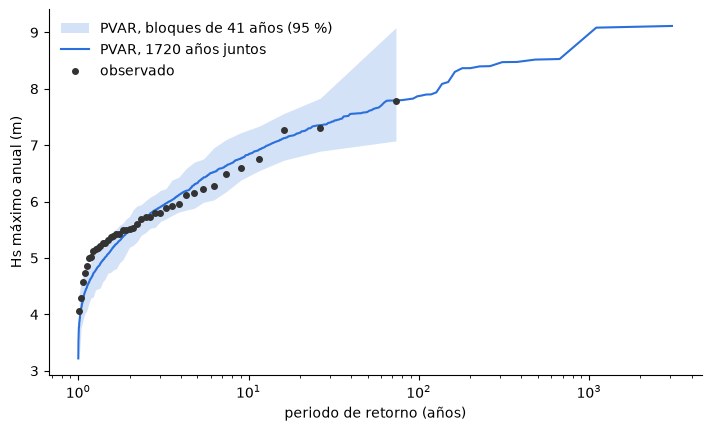

In [9]:
#### Curva empírica (Gringorten): todos los años simulados juntos, y bloques de 41 años (como la observación)
def gringorten(am):
    am = np.sort(np.asarray(am))
    n = len(am)
    return 1 / (1 - (np.arange(1, n + 1) - 0.44) / (n + 0.12)), am

am_obs = hs_obs.groupby(hs_obs.index.year).max()
T_obs, x_obs = gringorten(am_obs)
T_all, x_all = gringorten(am_hs.values.ravel())

n_b = len(am_obs)
bloques = [am_hs[c_].values[j:j + n_b] for c_ in am_hs.columns for j in range(0, len(am_hs) - n_b + 1, n_b)]
bloques_ord = np.array([np.sort(b) for b in bloques]).T          # (41, n bloques)
T_b = gringorten(np.arange(n_b))[0]

fig, ax = plt.subplots(figsize=(7, 4.2), constrained_layout=True)
ax.fill_between(T_b, np.percentile(bloques_ord, 2.5, axis=1), np.percentile(bloques_ord, 97.5, axis=1),
                color="#2a6fdb", alpha=0.2, lw=0, label="PVAR, bloques de 41 años (95 %)")
ax.plot(T_all, x_all, color="#2a6fdb", lw=1.5, label=f"PVAR, {am_hs.size} años juntos")
try:                                                               # f histórica + ruido (07), si existe
    hs_07 = pd.read_pickle(f"outputs/xgb_pit_{point}/hs_sims_1985_2025{SUF}.pkl")
    am_07 = hs_07.groupby(hs_07.index.year).max()
    ax.plot(T_b, np.median(np.sort(am_07.values, axis=0), axis=1), color="#d1495b", lw=1.2, ls="--", label="f histórica + ruido (07)")
except FileNotFoundError:
    pass
ax.plot(T_obs, x_obs, "o", color="0.2", ms=4, label="observado")
ax.set(xscale="log", xlabel="periodo de retorno (años)", ylabel="Hs máximo anual (m)")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left")
plt.show()

In [10]:
#### GEV: observado vs PVAR (bloques de 41 años, y todos los años juntos)
T_ret = np.array([2, 10, 50, 100, 500])

def gev(am):
    c_, loc, scale = genextreme.fit(am)
    return {"ξ": -c_, "μ": loc, "σ": scale, **{f"Hs{t}": genextreme.ppf(1 - 1 / t, c_, loc, scale) for t in T_ret}}

g_obs = pd.Series(gev(am_obs.values))
g_b = pd.DataFrame([gev(b) for b in bloques])
g_all = pd.Series(gev(am_hs.values.ravel()))
emp_all = pd.Series({f"Hs{t}": np.quantile(am_hs.values.ravel(), 1 - 1 / t) for t in T_ret if t <= am_hs.size / 2})

tabla_gev = pd.DataFrame({"obs (41 años)": g_obs, "PVAR bloques med": g_b.median(),
                          "PVAR bloques lo": g_b.quantile(0.025), "PVAR bloques hi": g_b.quantile(0.975),
                          f"PVAR todo ({am_hs.size} años)": g_all, "PVAR empírico": emp_all})
print(tabla_gev.round(2).to_string())

       obs (41 años)  PVAR bloques med  PVAR bloques lo  PVAR bloques hi  PVAR todo (1720 años)  PVAR empírico
Hs10            6.67              6.75             6.39             7.11                   6.79           6.83
Hs100           7.70              8.01             7.19             9.07                   8.01           7.86
Hs2             5.59              5.48             5.12             5.76                   5.48           5.48
Hs50            7.43              7.65             7.04             8.41                   7.69           7.58
Hs500           8.24              8.59             7.26            10.72                   8.65           8.50
μ               5.34              5.17             4.86             5.47                   5.18            NaN
ξ              -0.13             -0.15            -0.49             0.05                  -0.14            NaN
σ               0.68              0.80             0.65             1.02                   0.83            NaN


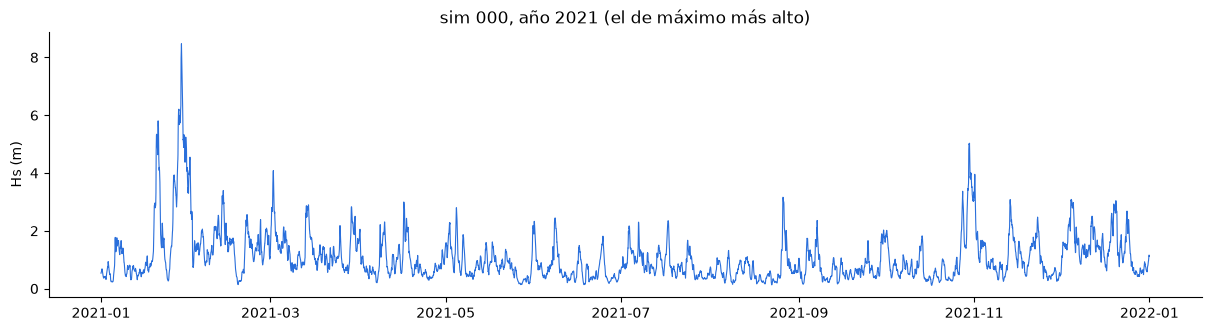

In [11]:
#### Ejemplo: un año de la primera simulación
hs0 = pd.read_parquet(f"outputs/xgb_pit_{point}/emulador{SUF}/sim_000.parquet")["VHM0"]
ano = hs0.groupby(hs0.index.year).max().idxmax()

fig, ax = plt.subplots(figsize=(12, 3.2), constrained_layout=True)
ax.plot(hs0.loc[str(ano)], color="#2a6fdb", lw=0.8)
ax.set(ylabel="Hs (m)", title=f"sim 000, año {ano} (el de máximo más alto)")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

#### TEST — ¿Por qué la f del PVAR es más débil? (máx. anual de f: 1.94 vs 2.61)

In [12]:
#### A. ¿Las PCs de 1941–1984 (que también entran en el PVAR) dan una f distinta a las de 1985–2025?
f_hist_largo = f_desde_pcs(pcs_hist.loc["1940-11-01":"2025-12-31"]).loc["1941":"2025"]
q = [0.5, 0.9, 0.99, 0.999]
tabla_A = pd.DataFrame({"1941–1984": f_hist_largo.loc[:"1984"].quantile(q), "1985–2025": f_hist_largo.loc["1985":].quantile(q)})
am_A = f_hist_largo.groupby(f_hist_largo.index.year).max()
print(tabla_A.round(3).to_string())
print(f"máx. anual de f: 1941–1984 {am_A.loc[:1984].mean():.2f} | 1985–2025 {am_A.loc[1985:].mean():.2f}")

#### B. Mismo PVAR, con innovaciones bootstrap (residuos reales: colas y dependencia entre PCs) en vez de gaussianas
var_h1 = pickle.load(open("outputs/var_6h/var_h2.pkl", "rb"))
harm_std_pcs = pickle.load(open("outputs/var_6h/harm_std_pcs.pkl", "rb"))
burn_pvar = int(pd.Timedelta(days=3*365) / pd.Timedelta("6h"))

res_B = {}
for draw in ["gaussian", "bootstrap"]:
    var_h1.noise_draw = draw
    qs, ams = [], []
    for i in range(5):
        sim_z = var_h1.simulate(n_years=87, start="1940-01-01", seed=i, burn=burn_pvar)
        f_b = f_desde_pcs(harm_std_pcs.inverse_transform(sim_z)).loc["1941":]
        qs.append(f_b.quantile(q))
        ams.append(f_b.groupby(f_b.index.year).max().mean())
    res_B[draw] = pd.concat(qs, axis=1).median(axis=1)
    print(f"{draw:9s}: máx. anual de f {np.mean(ams):.2f}")
var_h1.noise_draw = "gaussian"
print(pd.DataFrame({"f histórica 1985–2025": tabla_A["1985–2025"], **{f"PVAR {k}": v for k, v in res_B.items()}}).round(3).to_string())

       1941–1984  1985–2025
0.500     -0.023     -0.044
0.900      0.946      0.971
0.990      1.910      1.939
0.999      2.683      2.657
máx. anual de f: 1941–1984 2.69 | 1985–2025 2.66
gaussian : máx. anual de f 2.36
bootstrap: máx. anual de f 2.37
       f histórica 1985–2025  PVAR gaussian  PVAR bootstrap
0.500                 -0.044         -0.005          -0.012
0.900                  0.971          0.831           0.814
0.990                  1.939          1.706           1.682
0.999                  2.657          2.405           2.398


In [13]:
#### B rápido: ruido bootstrap mensual precalculado y pasado con noise=
def ruido_bootstrap_pvar(fechas, rng):
    out = np.empty((len(fechas), var_h1.k_))
    for m in range(1, 13):
        idx = np.flatnonzero(fechas.month == m)
        pool = var_h1.resid_month_[m]
        out[idx] = pool[rng.integers(len(pool), size=len(idx))]
    return pd.DataFrame(out, index=fechas, columns=var_h1.columns_)

fechas = pd.date_range("1940-01-01", periods=87 * 1461, freq="6h")
qs, ams = [], []
for i in range(5):
    sim_z = var_h1.simulate(noise=ruido_bootstrap_pvar(fechas, np.random.default_rng(i)), burn=burn_pvar)
    f_b = f_desde_pcs(harm_std_pcs.inverse_transform(sim_z)).loc["1941":]
    qs.append(f_b.quantile(q))
    ams.append(f_b.groupby(f_b.index.year).max().mean())
print(f"bootstrap: máx. anual de f {np.mean(ams):.2f}")
print(pd.concat(qs, axis=1).median(axis=1).round(3))

bootstrap: máx. anual de f 2.34
0.500   -0.023
0.900    0.817
0.990    1.675
0.999    2.394
dtype: float64


In [14]:
var_h1.n_harm

2

          std sim/hist  asim hist  asim sim  q999 sim/hist  q001 sim/hist
msl_PC4           1.00      -0.58     -0.42           1.12           1.00
msl_PC1           1.00       0.68      0.75           1.12           1.05
msl_PC3           1.01      -0.16     -0.19           0.97           1.03
msl_PC11          1.00       0.12      0.11           1.00           0.97
msl_PC6           1.01      -0.71     -0.57           1.16           1.00
msl_PC2           1.01      -0.86     -0.58           1.33           0.94
msl_PC34          1.00      -0.03     -0.02           0.96           0.97
msl_PC8           1.00       0.14      0.05           0.96           1.04
msl_PC27          1.00       0.08      0.11           0.98           0.94
msl_PC38          1.00      -0.03      0.00           0.98           0.95
msl_PC17          1.00       0.04     -0.00           0.96           0.99
msl_PC30          1.00       0.09      0.02           0.93           0.97
msl_PC13          1.00       0.18     

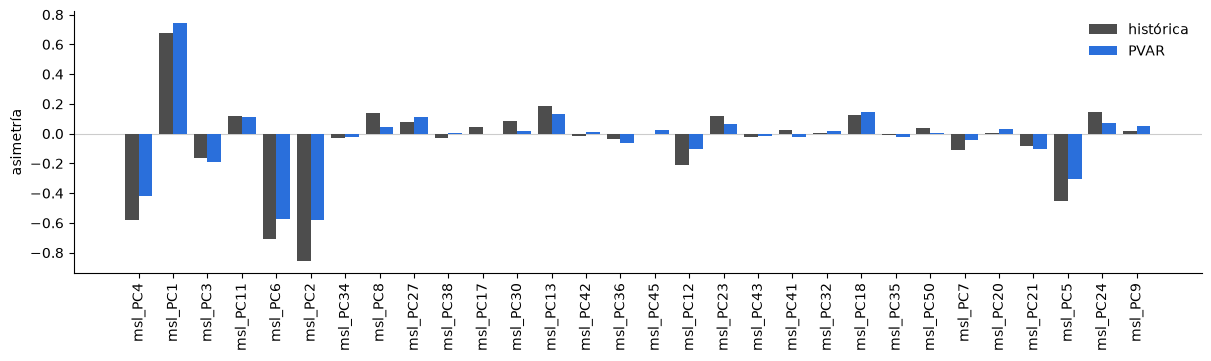

In [15]:
#### TEST C — PCs históricas vs simuladas por el PVAR: varianza, asimetría y colas
from scipy.stats import skew
ficheros = sorted(glob.glob("outputs/var_6h/simulaciones/sim_*.parquet"))

hist = pcs_hist.loc["1941":"2025"]
sims_pcs = pd.concat([pd.read_parquet(fic).astype("float64").loc["1941":] for fic in ficheros[:5]])

def resumen(df):
    return pd.DataFrame({"std": df.std(), "asim": df.apply(lambda x: skew(x)),
                         "q001": df.quantile(0.001), "q999": df.quantile(0.999)})

r_h, r_s = resumen(hist), resumen(sims_pcs)
tabla_C = pd.DataFrame({"std sim/hist": r_s["std"] / r_h["std"],
                        "asim hist": r_h["asim"], "asim sim": r_s["asim"],
                        "q999 sim/hist": r_s["q999"] / r_h["q999"],
                        "q001 sim/hist": r_s["q001"] / r_h["q001"]})
print(tabla_C.round(2).to_string())

fig, ax = plt.subplots(figsize=(12, 3.5), constrained_layout=True)
x = np.arange(len(tabla_C))
ax.bar(x - 0.2, tabla_C["asim hist"], width=0.4, color="0.3", label="histórica")
ax.bar(x + 0.2, tabla_C["asim sim"], width=0.4, color="#2a6fdb", label="PVAR")
ax.axhline(0, color="0.8", lw=0.8, zorder=0)
ax.set(xticks=x, ylabel="asimetría")
ax.set_xticklabels(tabla_C.index, rotation=90)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.show()

In [16]:
#### TEST D — Mapeo de cuantiles de cada PC simulada a su distribución histórica, por mes
def mapear_pcs(sim, hist):
    out = sim.copy()
    for m in range(1, 13):
        ms, mh = sim.index.month == m, hist.index.month == m
        for c_ in sim.columns:
            rk = (sim.loc[ms, c_].rank().values - 0.5) / ms.sum()
            out.loc[ms, c_] = np.quantile(hist.loc[mh, c_].values, rk)
    return out

qs_D, am_D = [], []
for fic in ficheros[:5]:
    pcs_m = mapear_pcs(pd.read_parquet(fic).astype("float64"), hist)
    f_m = f_desde_pcs(pcs_m).loc["1941":]
    qs_D.append(f_m.quantile(q))
    am_D.append(f_m.groupby(f_m.index.year).max().mean())
print(f"PVAR + mapeo de PCs: máx. anual de f {np.mean(am_D):.2f}  (histórica 2.61, PVAR sin mapeo 1.94)")
print(pd.concat(qs_D, axis=1).median(axis=1).round(3))

PVAR + mapeo de PCs: máx. anual de f 2.31  (histórica 2.61, PVAR sin mapeo 1.94)
0.500   -0.015
0.900    0.822
0.990    1.679
0.999    2.344
dtype: float64


In [17]:
#### Preparación: PCs con lags (como el XGB), históricas y simuladas, y su f
from sklearn.linear_model import LinearRegression
from scipy.stats import skew, norm

def con_lags(p):
    X = pd.concat({f"l{l}": p.shift(freq=pd.Timedelta(hours=l)) for l in lags}, axis=1).reindex(p.index)
    X.columns = [f"{c_}_l{l[1:]}" for l, c_ in X.columns]
    return X.dropna()[cols]

X_h = con_lags(pcs_hist.loc["1941":"2025"])
f_h6 = pd.Series(xgb_final.predict(X_h), index=X_h.index)
X_s = pd.concat([con_lags(pd.read_parquet(fic).astype("float64").loc["1941":]) for fic in ficheros[:5]])
f_s6 = pd.Series(xgb_final.predict(X_s), index=X_s.index)

#### Dirección "temporal": la combinación lineal de PCs (con lags) que mejor explica f
lr = LinearRegression().fit(X_h, f_h6)
w = lr.coef_ / np.linalg.norm(lr.coef_)
mu = X_h.mean().values
s_h, s_s = (X_h.values - mu) @ w, (X_s.values - mu) @ w

#### Dirección ortogonal: la de mayor varianza en lo que queda (para el eje y)
R = (X_h.values - mu) - np.outer(s_h, w)
v = np.linalg.svd(R[::20], full_matrices=False)[2][0]
o_h, o_s = (X_h.values - mu) @ v, (X_s.values - mu) @ v
sd = s_h.std()
s_h, s_s, o_h, o_s = s_h / sd, s_s / sd, o_h / o_h.std(), o_s / o_h.std()      # en unidades de σ histórica
print(f"R² de f con la dirección temporal: {lr.score(X_h, f_h6):.2f}")
print(f"asimetría de la componente temporal: hist {skew(s_h):.2f} | PVAR {skew(s_s):.2f}")

R² de f con la dirección temporal: 0.67
asimetría de la componente temporal: hist 0.33 | PVAR 0.09


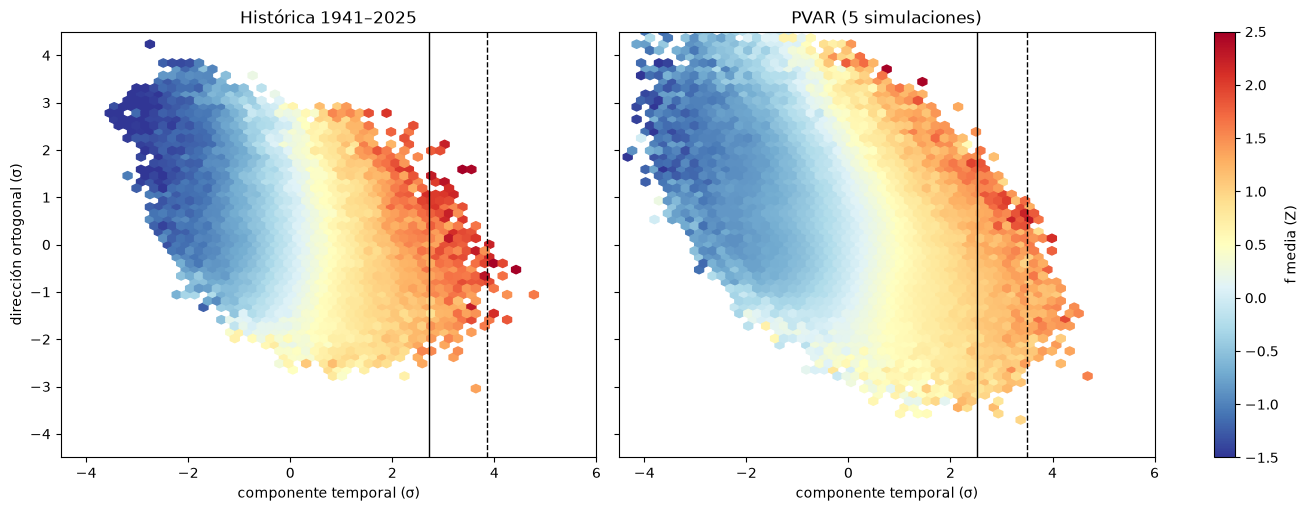

In [18]:
ext = (-4.5, 6, -4.5, 4.5)
fig, axs = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True, sharey=True)
for ax, s, o, f_, tit in [(axs[0], s_h, o_h, f_h6, "Histórica 1941–2025"), (axs[1], s_s, o_s, f_s6, "PVAR (5 simulaciones)")]:
    hb = ax.hexbin(s, o, C=f_.values, reduce_C_function=np.mean, gridsize=60, extent=ext,
                   cmap="RdYlBu_r", vmin=-1.5, vmax=2.5, mincnt=3)
    #### contorno del 99 % y 99.9 % de los puntos (dónde acaba la nube)
    for q, ls in [(0.99, "-"), (0.999, "--")]:
        ax.axvline(np.quantile(s, q), color="k", lw=1, ls=ls)
    ax.set(title=tit, xlabel="componente temporal (σ)", xlim=ext[:2], ylim=ext[2:])
axs[0].set_ylabel("dirección ortogonal (σ)")
fig.colorbar(hb, ax=axs, label="f media (Z)")
plt.show()

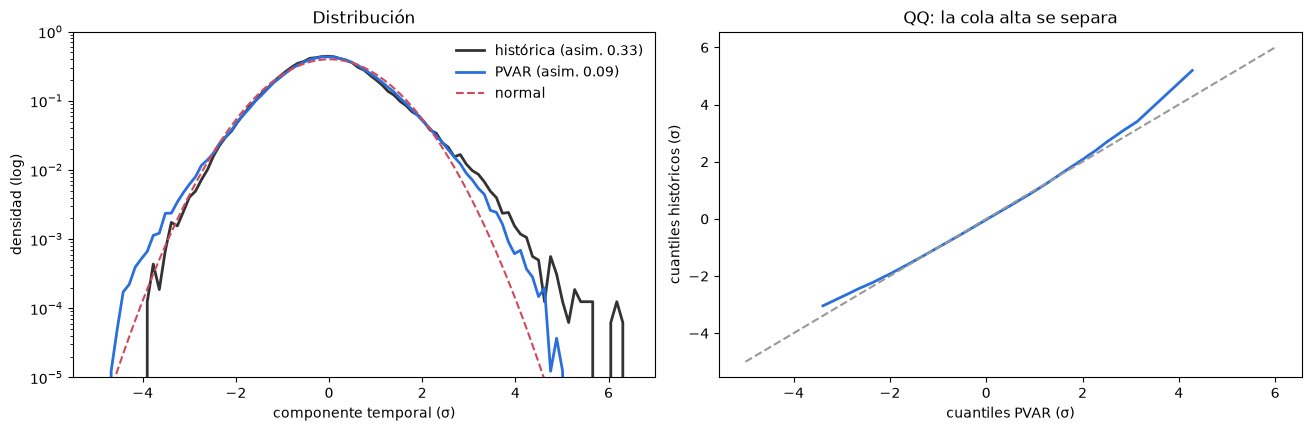

In [19]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2), constrained_layout=True)
b = np.linspace(-5, 6.5, 90); xc = (b[1:] + b[:-1]) / 2
for s, c, lab in [(s_h, "0.2", "histórica"), (s_s, "#2a6fdb", "PVAR")]:
    dens, _ = np.histogram(s, bins=b, density=True)
    axs[0].semilogy(xc, dens, color=c, lw=2, label=f"{lab} (asim. {skew(s):.2f})")
axs[0].semilogy(xc, norm.pdf(xc, s_s.mean(), s_s.std()), color="#d1495b", ls="--", label="normal")
axs[0].set(xlabel="componente temporal (σ)", ylabel="densidad (log)", ylim=(1e-5, 1), title="Distribución")
axs[0].legend(frameon=False)

qq = np.linspace(0.001, 0.9999, 400)
axs[1].plot(np.quantile(s_s, qq), np.quantile(s_h, qq), color="#2a6fdb", lw=2)
axs[1].plot([-5, 6], [-5, 6], color="0.6", ls="--")
axs[1].set(xlabel="cuantiles PVAR (σ)", ylabel="cuantiles históricos (σ)", title="QQ: la cola alta se separa")
plt.show()

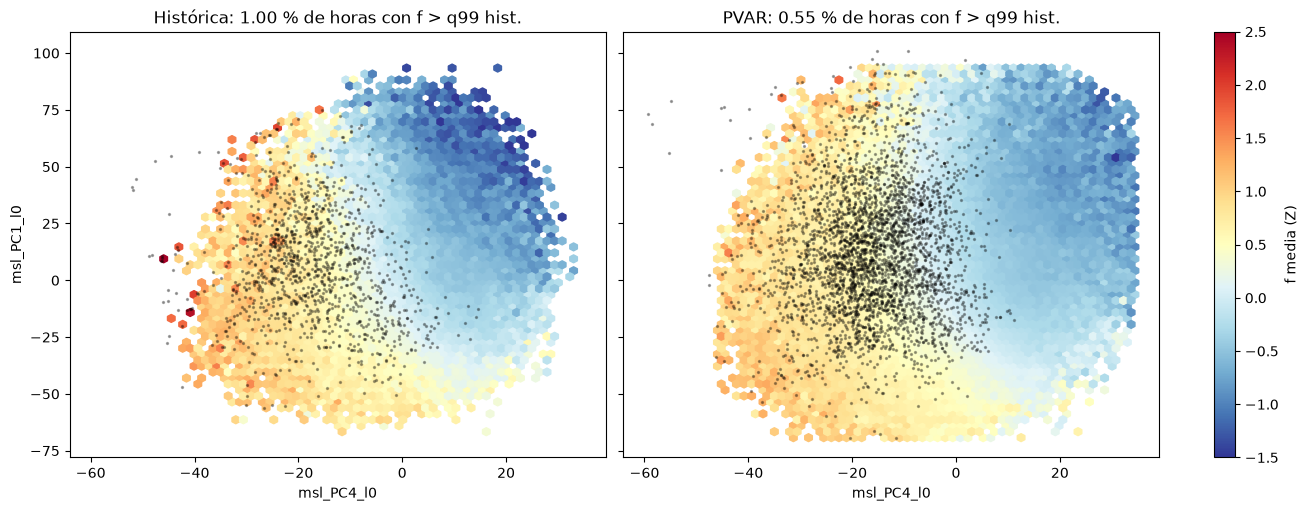

In [20]:
c1, c2 = "msl_PC4_l0", "msl_PC1_l0"
lim = [np.quantile(X_h[c], [0.0005, 0.9995]) for c in (c1, c2)]
fig, axs = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True, sharex=True, sharey=True)
for ax, X, f_, tit in [(axs[0], X_h, f_h6, "Histórica"), (axs[1], X_s, f_s6, "PVAR")]:
    hb = ax.hexbin(X[c1], X[c2], C=f_.values, reduce_C_function=np.mean, gridsize=55,
                   cmap="RdYlBu_r", vmin=-1.5, vmax=2.5, mincnt=3,
                   extent=(*lim[0], *lim[1]))
    top = f_ > f_h6.quantile(0.99)                                     # horas "de temporal" (umbral histórico)
    ax.scatter(X.loc[top, c1], X.loc[top, c2], s=2, color="k", alpha=0.3)
    ax.set(title=f"{tit}: {top.mean()*100:.2f} % de horas con f > q99 hist.", xlabel=c1)
axs[0].set_ylabel(c2)
fig.colorbar(hb, ax=axs, label="f media (Z)")
plt.show()